### BCSE432E Reinforcement Learning Lab: L29+L30
### Lab Assignment 2
### Grid World MDP - Value Iteration

### Name: Yashvanth Karunakaran (23BAI1589)

### AIM:
To implement the Value Iteration algorithm in a 10x10 Grid World environment to find the optimal value function and the optimal policy.

### Problem Description
- Grid Size: 10 by 10
- Start State: (0, 0)
- Goal State: (9, 9)
- Actions: Up, Down, Left, Right
- Movement: Stochastic, agent moves in the intended direction with an 80% chance, and with a 20% chance, it moves randomly among the other valid directions.
- Reward:
  - +10 for reaching the goal state.
  - -1 for every other step.
- Discount Factor (Gamma): 0.9
- Terminal State: The goal state is terminal.

### 1. Defining the MDP
State space for our 10x10 grid.

In [1]:
GRID_SIZE = 10
START_STATE = (0, 0)
GOAL_STATE = (9, 9)

STATES = [(r, c) for r in range(GRID_SIZE) for c in range(GRID_SIZE)]

### Actions and their coordinate changes.

In [2]:
ACTIONS = ['U', 'D', 'L', 'R']
ACTION_MOVES = {'U': (-1, 0), 'D': (1, 0), 'L': (0, -1), 'R': (0, 1)}

### Function to check valid states

In [3]:
def is_valid_state(r, c):
    return 0 <= r < GRID_SIZE and 0 <= c < GRID_SIZE

### Function determine next states

In [4]:
def get_next_state(r, c, action):
    dr, dc = ACTION_MOVES[action]
    next_r, next_c = r + dr, c + dc
    if is_valid_state(next_r, next_c):
        return next_r, next_c
    return r, c


### Function to get valid actions

In [5]:
def get_valid_actions(r, c):
    valid = []
    for action in ACTIONS:
        dr, dc = ACTION_MOVES[action]
        if is_valid_state(r + dr, c + dc):
            valid.append(action)
    return valid

### Function to compute transition probabilities according to the 80% / 20% stochastic movement rule.

In [6]:
def get_transition_probabilities(r, c, intended_action):
    if (r, c) == GOAL_STATE:
        return []
        
    valid_actions = get_valid_actions(r, c)
    transitions = []
    
    next_r, next_c = get_next_state(r, c, intended_action)
    transitions.append((0.8, next_r, next_c))
    
    other_valid_actions = [a for a in valid_actions if a != intended_action]
    
    if len(other_valid_actions) > 0:
        prob_other = 0.2 / len(other_valid_actions)
        for action in other_valid_actions:
            nr, nc = get_next_state(r, c, action)
            transitions.append((prob_other, nr, nc))
    else:
        transitions[0] = (1.0, next_r, next_c)
        
    return transitions

### Function to return reward

In [7]:
def get_reward(r, c):
    if (r, c) == GOAL_STATE:
        return 10
    return -1

### Testing transition probabilities for a sample state

In [8]:
for prob, nr, nc in get_transition_probabilities(5, 5, 'R'):
    print(f"P(next=({nr}, {nc}), action='R') = {prob}")

P(next=(5, 6), action='R') = 0.8
P(next=(4, 5), action='R') = 0.06666666666666667
P(next=(6, 5), action='R') = 0.06666666666666667
P(next=(5, 4), action='R') = 0.06666666666666667


## 2. Value Iteration Algorithm
We implement the Value Iteration loop using the Bellman update equation.

In [9]:
import numpy as np

THRESHOLD = 1e-4

def value_iteration(gamma=0.9):
    V = np.zeros((GRID_SIZE, GRID_SIZE))
    policy = np.full((GRID_SIZE, GRID_SIZE), ' ')
    policy[GOAL_STATE] = 'G'
    
    iteration = 0
    while True:
        delta = 0
        new_V = np.copy(V)
        
        for r in range(GRID_SIZE):
            for c in range(GRID_SIZE):
                if (r, c) == GOAL_STATE:
                    continue
                
                action_values = []
                for action in ACTIONS:
                    expected_value = 0

                    for prob, nr, nc in get_transition_probabilities(r, c, action):
                        expected_value += prob * (get_reward(nr, nc) + gamma * V[nr, nc])
                    action_values.append(expected_value)
                
                best_value = max(action_values)
                new_V[r, c] = best_value
                policy[r, c] = ACTIONS[np.argmax(action_values)]
                
                delta = max(delta, abs(best_value - V[r, c]))
                
        V = new_V
        iteration += 1
        if delta < THRESHOLD:
            print(f"Converged after {iteration} iterations for gamma = {gamma}")
            break
            
    return V, policy

### Run the Value Iteration with the default discount factor (0.9).

In [10]:
V_09, policy_09 = value_iteration(gamma=0.9)

Converged after 43 iterations for gamma = 0.9


### Optimal Value Function (Gamma = 0.9)
Displaying the final value function as a dataframe for a clean grid view.

In [11]:
from IPython.display import display
import pandas as pd

df_values = pd.DataFrame(V_09)
display(df_values.round(2))

,0,1,2,3,4,5,6,7,8,9
0,-8.04,-7.82,-7.52,-7.17,-6.77,-6.32,-5.81,-5.23,-4.67,-4.40
1,-7.82,-7.59,-7.25,-6.85,-6.38,-5.86,-5.25,-4.57,-3.90,-3.55
2,-7.52,-7.25,-6.86,-6.39,-5.86,-5.25,-4.55,-3.76,-2.96,-2.51
3,-7.17,-6.85,-6.39,-5.86,-5.25,-4.54,-3.74,-2.83,-1.87,-1.28
4,-6.77,-6.38,-5.86,-5.25,-4.54,-3.74,-2.81,-1.76,-0.62,0.16
5,-6.32,-5.86,-5.25,-4.54,-3.74,-2.81,-1.75,-0.53,0.81,1.85
6,-5.81,-5.25,-4.55,-3.74,-2.81,-1.75,-0.52,0.88,2.46,3.83
7,-5.23,-4.57,-3.76,-2.83,-1.76,-0.53,0.88,2.49,4.34,6.17
8,-4.67,-3.90,-2.96,-1.87,-0.62,0.81,2.46,4.34,6.49,8.94
9,-4.40,-3.55,-2.51,-1.28,0.16,1.85,3.83,6.17,8.94,0.00


### Optimal Policy (Gamma = 0.9)
Displaying the optimal policy (U, D, L, R).

In [12]:
df_policy = pd.DataFrame(policy_09)
display(df_policy)

,0,1,2,3,4,5,6,7,8,9
0,D,R,R,R,R,R,R,D,D,D
1,D,D,R,R,R,R,D,D,D,D
2,D,D,D,R,R,D,D,D,D,D
3,D,D,D,D,D,D,D,D,D,D
4,D,D,D,R,D,D,D,D,D,D
5,D,D,R,R,R,R,D,D,D,D
6,D,R,R,R,R,R,R,D,D,D
7,R,R,R,R,R,R,R,D,D,D
8,R,R,R,R,R,R,R,R,D,D
9,R,R,R,R,R,R,R,R,R,G


## 3. Visualization
Visualizing the value function using a heatmap and show the policy on the grid.

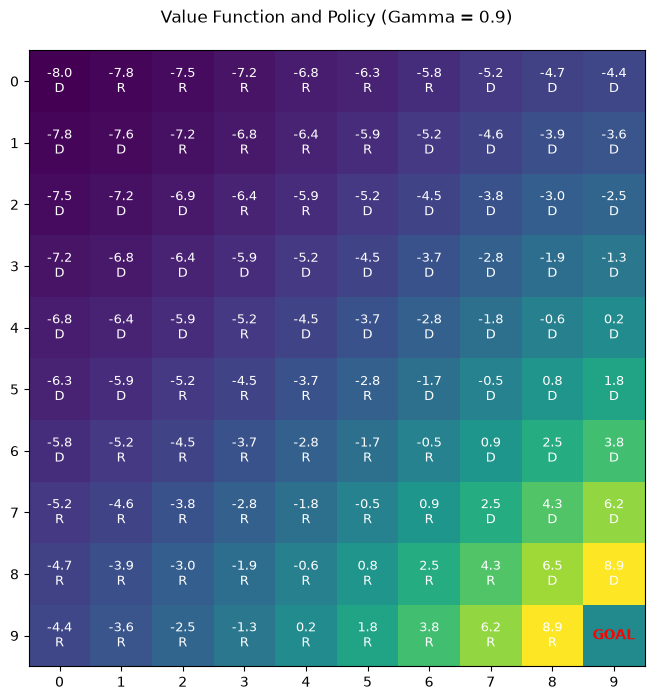

In [13]:
import matplotlib.pyplot as plt

def plot_results(V, policy, gamma_val):
    plt.figure(figsize=(8, 8))
    
    plt.imshow(V)
    
    for r in range(GRID_SIZE):
        for c in range(GRID_SIZE):
            if (r, c) == GOAL_STATE:
                plt.text(c, r, 'GOAL', ha='center', va='center', color='red', weight='bold')
                continue
            
            val = round(V[r, c], 1)
            action = policy[r, c]
            plt.text(c, r, f"{val}\n{action}", ha='center', va='center', color='white', fontsize=9)
    
    plt.title(f"Value Function and Policy (Gamma = {gamma_val})", pad=20)
    plt.xticks(range(GRID_SIZE))
    plt.yticks(range(GRID_SIZE))
    plt.show()


plot_results(V_09, policy_09, 0.9)

## 4. Experiment with Different Discount Factors
We will compute and visualize the value functions for gamma = 0 and gamma = 1.

Converged after 2 iterations for gamma = 0
Optimal Value Function (Gamma = 0):


,0,1,2,3,4,5,6,7,8,9
0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
2,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
3,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
4,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
5,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
6,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
7,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
8,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,7.8
9,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,7.8,0.0


Optimal Policy (Gamma = 0):


,0,1,2,3,4,5,6,7,8,9
0,U,U,U,U,U,U,U,U,U,U
1,U,U,U,U,U,U,U,U,U,U
2,U,U,U,U,U,U,U,U,U,U
3,U,U,U,U,U,U,U,U,U,U
4,U,U,U,U,U,U,U,U,U,U
5,U,U,U,U,U,U,U,U,U,U
6,U,U,U,U,U,U,U,U,U,U
7,U,U,U,U,U,U,U,U,U,U
8,U,U,U,U,U,U,U,U,U,D
9,U,U,U,U,U,U,U,U,R,G


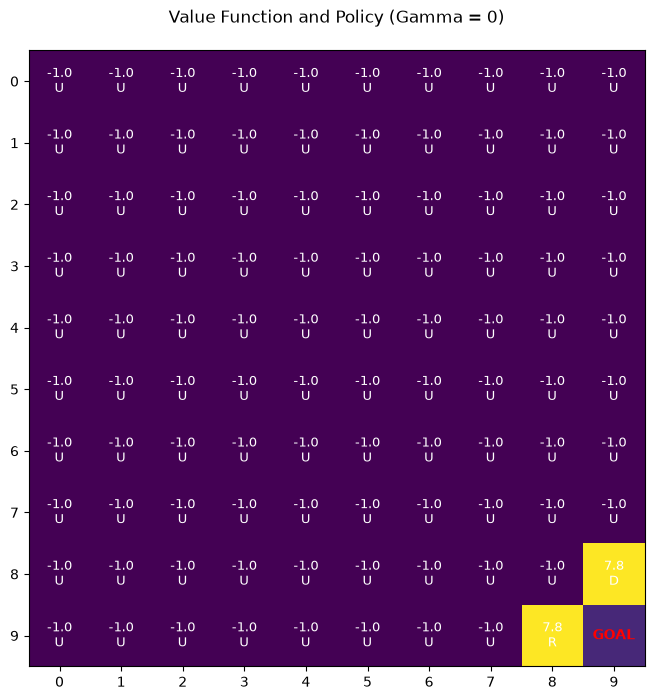

In [14]:
V_0, policy_0 = value_iteration(gamma=0)

print("Optimal Value Function (Gamma = 0):")
display(pd.DataFrame(V_0))

print("Optimal Policy (Gamma = 0):")
display(pd.DataFrame(policy_0))

plot_results(V_0, policy_0, 0)

Converged after 55 iterations for gamma = 1.0
Optimal Value Function (Gamma = 1):


,0,1,2,3,4,5,6,7,8,9
0,-12.865073,-11.865008,-10.606759,-9.321113,-8.037916,-6.761810,-5.494693,-4.238416,-3.164123,-2.717016
1,-11.865008,-10.930993,-9.633415,-8.301065,-6.963480,-5.622654,-4.277766,-2.965668,-1.835724,-1.355239
2,-10.606759,-9.633415,-8.350734,-6.999539,-5.641387,-4.281281,-2.923624,-1.594425,-0.420903,0.125044
3,-9.321113,-8.301065,-6.999539,-5.644661,-4.282368,-2.919296,-1.558406,-0.217182,0.999297,1.628323
4,-8.037916,-6.963480,-5.641387,-4.282368,-2.919182,-1.555614,-0.192999,1.157984,2.416602,3.144861
5,-6.761810,-5.622654,-4.281281,-2.919296,-1.555614,-0.191895,1.171755,2.530278,3.828907,4.675461
6,-5.494693,-4.277766,-2.923624,-1.558406,-0.192999,1.171755,2.535911,3.899628,5.234272,6.222605
7,-4.238416,-2.965668,-1.594425,-0.217182,1.157984,2.530278,3.899628,5.266163,6.630245,7.789539
8,-3.164123,-1.835724,-0.420903,0.999297,2.416602,3.828907,5.234272,6.630245,8.013642,9.380318
9,-2.717016,-1.355239,0.125044,1.628323,3.144861,4.675461,6.222605,7.789539,9.380318,0.000000



Optimal Policy (Gamma = 1):


,0,1,2,3,4,5,6,7,8,9
0,R,R,R,R,R,R,R,D,D,D
1,D,D,R,R,R,R,D,D,D,D
2,D,D,R,R,R,D,D,D,D,D
3,D,D,D,R,D,D,D,D,D,D
4,D,D,D,R,D,D,D,D,D,D
5,D,D,R,R,R,D,D,D,D,D
6,D,R,R,R,R,R,D,D,D,D
7,R,R,R,R,R,R,R,D,D,D
8,R,R,R,R,R,R,R,R,R,D
9,R,R,R,R,R,R,R,R,R,G


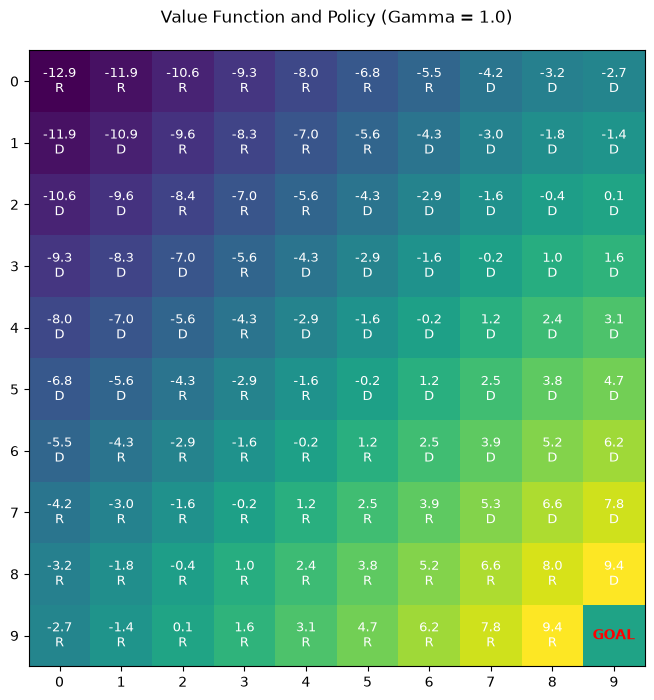

In [ ]:
V_1, policy_1 = value_iteration(gamma=1.0)

print("Optimal Value Function (Gamma = 1):")
display(pd.DataFrame(V_1))

print("Optimal Policy (Gamma = 1):")
display(pd.DataFrame(policy_1))

plot_results(V_1, policy_1, 1.0)

## 5. Observations

#### For gamma = 0
The agent only cares about the immediate reward. Because every normal step costs -1, and only the states right next to the goal can reach the +10 reward immediately, the agent doesn't know how to reach the goal from far away. Most of the grid just shows the immediate -1 penalty.

#### For gamma = 1
The agent considers long-term rewards fully without discounting them over time. The values smoothly increase as we get closer to the goal because the agent accurately calculates the total steps (and penalties) needed to reach the end.

With a higher gamma, the value propagates backward from the goal state to the start state, creating a clear gradient that guides the agent to the optimal path.

## 6. Conclusion
Therefore, successfully implemented the Value Iteration algorithm to find the optimal path in a 10x10 Grid World. We learned how the Bellman equation helps us iteratively find the correct value for each state. Finally, by experimenting with different discount factors, we observed how the agent's behavior shifts from short-sighted (gamma = 0) to long-term planning (gamma = 1).